# Adım 6: PubMed Literatür Kütüphanesi (MedCPT + FAISS)

RAG'ın ikinci ayağı. Adım 4'teki görüntü arşivi "bu vakaya benzeyen geçmiş vakalar hangileri?" sorusunu cevaplıyordu. Bu kütüphane ise şunu cevaplayacak: **"Bu konuda bilimsel literatür ne diyor?"** Örneğin: "Melanomu atipik nevüsten ayıran dermoskopik bulgular nelerdir?"

**Adımlar:**
1. **Toplama:** NCBI E-utilities (Biopython `Entrez`) ile 7 tanı sınıfının dermoskopisi, melanomun nevüsten ayrımı ve melanom risk faktörleri hakkında makale özetleri indirilir.
2. **Temizleme:** Özeti olmayan, çok kısa olan ve geri çekilmiş (retracted) makaleler çıkarılır; aynı makale birden fazla sorguda geldiyse tek kayıt tutulur.
3. **Vektöre çevirme:** **MedCPT** (NCBI'ın 255 milyon PubMed arama kaydıyla eğitilmiş tıbbi arama modeli) ile her makalenin başlığı ve özeti 768 boyutlu bir vektöre çevrilir.
4. **FAISS indeksi:** Vektörler iç çarpım indeksine konur (MedCPT iç çarpımla çalışır).
5. **İki aşamalı arama:** Sorgu kodlayıcıyla 50 aday bulunur, ardından **MedCPT çapraz kodlayıcı** sorgu ile her adayı birlikte okuyup yeniden sıralar. Bu daha yavaş ama daha isabetlidir.

**Bilinçli tercihler:**
- **Yapay zekâ makaleleri hariç** ("deep learning", "neural network" vb.). Literatür ajanının ihtiyacı klinik bilgi (dermoskopik bulgular, ayırıcı tanı, risk faktörleri); model başarımı tartışan makaleler değil.
- **Yıl aralığı 2000-2025 olarak sabit.** Kütüphane yeniden indirildiğinde de aynı makale kümesi çıksın diye.
- **Değerlendirme (önceden yazıldı):** Her sınıf için 3 klinik soru (toplam 21) önceden belirlendi. İlk 5 sonucun ne kadarının ilgili sınıfın sorgusundan geldiği ölçülür (sınıf isabeti@5). Bu kaba bir ölçüdür; gerçek "ilgililik" etiketi yoktur. Bu yüzden örnek sonuçlar da gözle incelenir.

**Başlamadan önce (bir kez):** Colab'ın sol menüsünde 🔑 **Gizli anahtarlar (Secrets)** bölümüne:
- `NCBI_EMAIL`: e-posta adresin (NCBI kimin indirdiğini bilmek ister; **zorunlu**).
- `NCBI_API_KEY` (isteğe bağlı): NCBI hesabından alınan anahtar. Olursa saniyede 3 yerine 10 istek yapılır.

Her iki anahtarın yanındaki "Not defteri erişimi" düğmesini aç. E-posta ve anahtar kodda yazmaz, GitHub'a gitmez.

**Çalışma zamanı:** GPU (T4 yeterli). Süre yaklaşık 15-25 dakika.

## 1. Ortam ve ayarlar

In [1]:
!pip -q install biopython faiss-cpu
import os, sys, io, re, json, time, importlib, warnings
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import faiss
from Bio import Entrez
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification

from google.colab import drive, userdata
drive.mount('/content/drive')
PROJE = '/content/drive/MyDrive/bitirme'
try:
    Entrez.email = userdata.get('NCBI_EMAIL')
except Exception:
    raise RuntimeError('Colab Secrets içinde NCBI_EMAIL bulunamadı. Defterin başındaki talimatı uygula.')
try:
    Entrez.api_key = userdata.get('NCBI_API_KEY')
except Exception:
    print('NCBI_API_KEY yok: saniyede 3 istekle devam ediliyor (biraz daha yavaş, sorun değil).')

# ---- Ayarlar (sonuçlara bakmadan sabitlendi) ----
BASLANGIC_YILI, BITIS_YILI = 2000, 2025
SORGU_BASINA = 1000          # her toplama sorgusundan en ilgili bu kadar makale
PARTI = 200                  # bir istekte indirilecek makale sayısı
EN_KISA_OZET = 150           # karakter; daha kısa özetler atılır
MAKALE_MODELI = 'ncbi/MedCPT-Article-Encoder'
SORGU_MODELI = 'ncbi/MedCPT-Query-Encoder'
CAPRAZ_MODEL = 'ncbi/MedCPT-Cross-Encoder'
KODLAMA_PARTISI = 32
ON = '06'
KLASOR = f'{PROJE}/rag'
os.makedirs(KLASOR, exist_ok=True); os.makedirs(f'{PROJE}/src', exist_ok=True)
CIHAZ = 'cuda' if torch.cuda.is_available() else 'cpu'
warnings.filterwarnings('ignore', category=FutureWarning)
print('Cihaz:', CIHAZ, '| torch', torch.__version__)

Mounted at /content/drive
NCBI_API_KEY yok: saniyede 3 istekle devam ediliyor (biraz daha yavaş, sorun değil).
Cihaz: cuda | torch 2.14.1+cu130


## 2. Toplama sorguları
Her sorgu bir ya da birkaç tanı sınıfıyla etiketlenir. Bir makale birden fazla sorguda gelirse bütün etiketleri tutulur. Ortak filtreler: özeti olan, İngilizce, 2000-2025 arası, yapay zekâ makaleleri hariç.

In [2]:
DERMOSKOPI = '(dermoscopy[tiab] OR dermoscopic[tiab] OR dermatoscopy[tiab] OR dermatoscopic[tiab] OR epiluminescence[tiab])'
ORTAK = (f'hasabstract[text] AND english[la] AND ("{BASLANGIC_YILI}"[dp] : "{BITIS_YILI}"[dp]) '
         'NOT ("deep learning"[tiab] OR "machine learning"[tiab] OR "neural network"[tiab] OR "artificial intelligence"[tiab] '
         'OR "convolutional"[tiab] OR "computer-aided"[tiab])')
TOPLAMA_SORGULARI = {
    'melanom':          ('melanoma[tiab] AND ' + DERMOSKOPI, ['mel']),
    'nevus':            ('(nevus[tiab] OR nevi[tiab] OR naevus[tiab] OR naevi[tiab]) AND ' + DERMOSKOPI, ['nv']),
    'melanom_nevus':    ('melanoma[tiab] AND (nevus[tiab] OR nevi[tiab] OR naevi[tiab]) AND (differential[tiab] OR distinguish*[tiab] OR discriminat*[tiab] OR mimic*[tiab])', ['mel', 'nv']),
    'bcc':              ('"basal cell carcinoma"[tiab] AND ' + DERMOSKOPI, ['bcc']),
    'akiec':            ('("actinic keratosis"[tiab] OR "actinic keratoses"[tiab] OR "Bowen disease"[tiab] OR "Bowen\'s disease"[tiab] '
                         'OR "intraepidermal carcinoma"[tiab] OR "squamous cell carcinoma in situ"[tiab]) AND ' + DERMOSKOPI, ['akiec']),
    'bkl':              ('("seborrheic keratosis"[tiab] OR "seborrhoeic keratosis"[tiab] OR "seborrheic keratoses"[tiab] OR "solar lentigo"[tiab] '
                         'OR "lichen planus-like keratosis"[tiab]) AND ' + DERMOSKOPI, ['bkl']),
    'df':               ('(dermatofibroma[tiab] OR dermatofibromas[tiab] OR "fibrous histiocytoma"[tiab]) AND ' + DERMOSKOPI, ['df']),
    'vasc':             ('(hemangioma[tiab] OR haemangioma[tiab] OR angiokeratoma[tiab] OR "pyogenic granuloma"[tiab] OR "cherry angioma"[tiab] '
                         'OR "vascular lesion"[tiab] OR "vascular lesions"[tiab]) AND ' + DERMOSKOPI, ['vasc']),
    'melanom_risk':     ('melanoma[tiab] AND ("risk factor"[tiab] OR "risk factors"[tiab]) AND (age[tiab] OR "anatomic site"[tiab] OR "body site"[tiab] OR sex[tiab])', ['mel']),
}
print(f'{len(TOPLAMA_SORGULARI)} toplama sorgusu tanımlandı.')

9 toplama sorgusu tanımlandı.


## 3. PubMed'den indirme
`esearch` her sorgu için en ilgili makalelerin kimliklerini (PMID) döndürür, `efetch` bu makalelerin başlık, özet, dergi, yıl, MeSH terimleri ve yayın türlerini XML olarak getirir. Biopython, NCBI'ın istek sınırına (saniyede 3 ya da 10) kendiliğinden uyar. Ağ hatalarında 3 kez yeniden denenir.

In [3]:
def tekrar_dene(fonk, deneme=3):
    for i in range(deneme):
        try:
            return fonk()
        except Exception as hata:
            if i == deneme - 1:
                raise
            print(f'  ağ hatası ({hata!r}), {5 * (i + 1)} sn sonra yeniden deneniyor...'); time.sleep(5 * (i + 1))

def pmid_ara(sorgu, n):
    def istek():
        with Entrez.esearch(db='pubmed', term=f'({sorgu}) AND {ORTAK}', retmax=n, sort='relevance') as h:
            return h.read()
    kok = ET.fromstring(tekrar_dene(istek))
    return [e.text for e in kok.findall('./IdList/Id')], int(kok.findtext('Count', '0'))

def metin(e):
    return ' '.join(''.join(e.itertext()).split()) if e is not None else ''

def makale_ayristir(art):
    mc = art.find('MedlineCitation'); a = mc.find('Article')
    parcalar = []
    for p in a.findall('./Abstract/AbstractText'):
        etiket = p.get('Label')
        parcalar.append(f'{etiket}: {metin(p)}' if etiket else metin(p))
    tarih = a.find('./Journal/JournalIssue/PubDate')
    yil = tarih.findtext('Year') if tarih is not None else None
    if not yil and tarih is not None:
        m = re.search(r'(19|20)\d{2}', tarih.findtext('MedlineDate', ''))
        yil = m.group(0) if m else None
    return {'pmid': mc.findtext('PMID'), 'baslik': metin(a.find('ArticleTitle')), 'ozet': ' '.join(parcalar),
            'dergi': metin(a.find('./Journal/Title')), 'yil': int(yil) if yil else None,
            'mesh': '; '.join(metin(d) for d in mc.findall('./MeshHeadingList/MeshHeading/DescriptorName')),
            'yayin_turu': '; '.join(metin(t) for t in a.findall('./PublicationTypeList/PublicationType'))}

def makaleleri_getir(pmidler):
    kayitlar = []
    for i in range(0, len(pmidler), PARTI):
        def istek(parti=pmidler[i:i + PARTI]):
            with Entrez.efetch(db='pubmed', id=','.join(parti), retmode='xml') as h:
                return h.read()
        kok = ET.fromstring(tekrar_dene(istek))
        kayitlar += [makale_ayristir(art) for art in kok.findall('PubmedArticle')]
    return kayitlar

t0 = time.time()
etiketler, sorgu_ozeti = {}, []
for ad, (sorgu, siniflar) in TOPLAMA_SORGULARI.items():
    pmidler, toplam = pmid_ara(sorgu, SORGU_BASINA)
    for p in pmidler:
        etiketler.setdefault(p, set()).update(siniflar)
    sorgu_ozeti.append({'sorgu': ad, 'siniflar': ','.join(siniflar), 'pubmed_toplam': toplam, 'alinan': len(pmidler)})
    print(f'{ad:15s}: PubMed\'de {toplam:5d} makale, en ilgili {len(pmidler)} alındı')
print(f'\nTekil makale: {len(etiketler)} | arama süresi {time.time() - t0:.0f} sn')

t0 = time.time()
ham = pd.DataFrame(makaleleri_getir(sorted(etiketler)))
print(f'İndirilen kayıt: {len(ham)} | süre {(time.time() - t0) / 60:.1f} dk')

melanom        : PubMed'de  1968 makale, en ilgili 1000 alındı
nevus          : PubMed'de  1167 makale, en ilgili 1000 alındı
melanom_nevus  : PubMed'de  1165 makale, en ilgili 1000 alındı
bcc            : PubMed'de   547 makale, en ilgili 547 alındı
akiec          : PubMed'de   315 makale, en ilgili 315 alındı
bkl            : PubMed'de   261 makale, en ilgili 261 alındı
df             : PubMed'de    99 makale, en ilgili 99 alındı
vasc           : PubMed'de   129 makale, en ilgili 129 alındı
melanom_risk   : PubMed'de  1459 makale, en ilgili 1000 alındı

Tekil makale: 4140 | arama süresi 6 sn
İndirilen kayıt: 4133 | süre 0.6 dk


## 4. Temizleme

Ham: 4133 | geri çekilmiş: 1 | özeti çok kısa: 3 | KALAN: 4129
Sınıf etiketine göre makale sayısı (bir makale birden fazla sınıfta olabilir): {'akiec': 315, 'bcc': 545, 'bkl': 260, 'df': 99, 'mel': 2859, 'nv': 1848, 'vasc': 129}


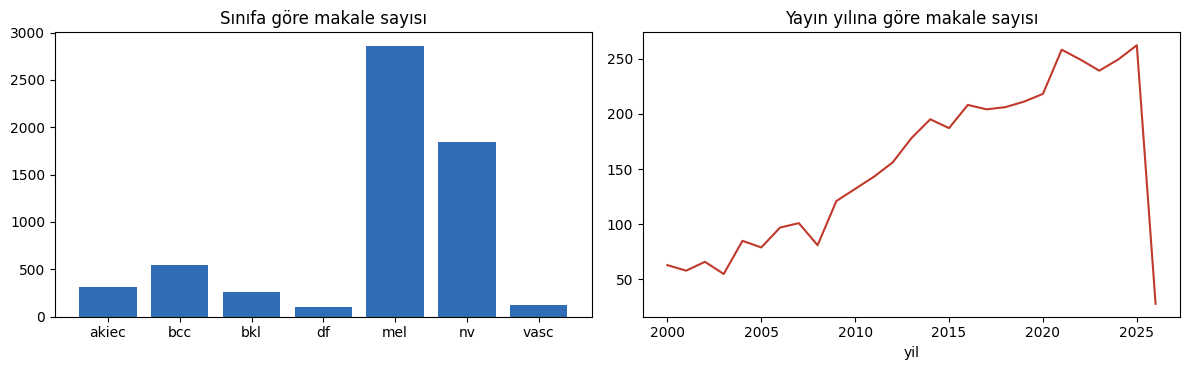

In [4]:
ham = ham.drop_duplicates('pmid')
ham['etiketler'] = ham['pmid'].map(lambda p: ','.join(sorted(etiketler.get(p, []))))
geri_cekilmis = ham['yayin_turu'].str.contains('Retracted Publication|Retraction of Publication', regex=True)
kisa = ham['ozet'].str.len() < EN_KISA_OZET
makaleler = ham[~geri_cekilmis & ~kisa].reset_index(drop=True)
print(f'Ham: {len(ham)} | geri çekilmiş: {int(geri_cekilmis.sum())} | özeti çok kısa: {int((kisa & ~geri_cekilmis).sum())} | KALAN: {len(makaleler)}')

sinif_sayisi = {s: int(makaleler['etiketler'].str.split(',').apply(lambda e: s in e).sum())
                for s in ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']}
print('Sınıf etiketine göre makale sayısı (bir makale birden fazla sınıfta olabilir):', sinif_sayisi)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(list(sinif_sayisi), list(sinif_sayisi.values()), color='#2F6DB5'); ax[0].set_title('Sınıfa göre makale sayısı')
makaleler['yil'].dropna().astype(int).value_counts().sort_index().plot(ax=ax[1], color='#C0392B'); ax[1].set_title('Yayın yılına göre makale sayısı')
plt.tight_layout(); plt.savefig(f'{PROJE}/results/{ON}_pubmed_dagilim.png', dpi=150); plt.show()

## 5. MedCPT ile vektöre çevirme
Makale kodlayıcı başlık ve özeti birlikte okur (en fazla 512 parça/token), ilk parçanın ([CLS]) çıktısı makalenin vektörüdür. Özetin 512 parçadan uzun olan kısmı kesilir; aşağıda kaç makalenin kesildiği raporlanır.

In [5]:
m_tok = AutoTokenizer.from_pretrained(MAKALE_MODELI)
m_model = AutoModel.from_pretrained(MAKALE_MODELI).to(CIHAZ).eval()

uzunluk = [len(m_tok(b, o, truncation=False)['input_ids']) for b, o in zip(makaleler['baslik'], makaleler['ozet'])]
print(f'512 parçadan uzun olduğu için kesilen makale: %{100 * np.mean(np.array(uzunluk) > 512):.1f} (ortanca uzunluk {int(np.median(uzunluk))})')

@torch.no_grad()
def makale_vektoru(basliklar, ozetler):
    cikti = []
    for i in range(0, len(basliklar), KODLAMA_PARTISI):
        g = m_tok(list(basliklar[i:i + KODLAMA_PARTISI]), list(ozetler[i:i + KODLAMA_PARTISI]),
                  truncation=True, padding=True, max_length=512, return_tensors='pt').to(CIHAZ)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(CIHAZ == 'cuda')):
            cikti.append(m_model(**g).last_hidden_state[:, 0, :].float().cpu().numpy())
    return np.concatenate(cikti).astype('float32')

t0 = time.time()
GOMME = makale_vektoru(makaleler['baslik'].tolist(), makaleler['ozet'].tolist())
print(f'Vektörler: {GOMME.shape} | süre {(time.time() - t0) / 60:.1f} dk')

indeks = faiss.IndexFlatIP(GOMME.shape[1])
indeks.add(GOMME)
faiss.write_index(indeks, f'{KLASOR}/pubmed.faiss')
np.save(f'{KLASOR}/pubmed_gomme.npy', GOMME)
makaleler.to_parquet(f'{KLASOR}/pubmed_makaleler.parquet', index=False)
del m_model
if CIHAZ == 'cuda':
    torch.cuda.empty_cache()
print('Kütüphanedeki makale sayısı:', indeks.ntotal)

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.49k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/226k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/706k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/74.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

512 parçadan uzun olduğu için kesilen makale: %5.1 (ortanca uzunluk 313)
Vektörler: (4129, 768) | süre 0.6 dk
Kütüphanedeki makale sayısı: 4129


## 6. Arama modülü
Arama kodu Drive'da `src/pubmed_arama.py` dosyasına yazılır. Literatür ajanı ve web arayüzü aynı dosyayı kullanacak. Dosya GitHub'daki `src/` klasörüne de konacak.

In [6]:
%%writefile /content/drive/MyDrive/bitirme/src/pubmed_arama.py
"""PubMed literatür kütüphanesinde arama: MedCPT sorgu kodlayıcı + FAISS (iç çarpım) + isteğe bağlı MedCPT çapraz kodlayıcı ile yeniden sıralama."""
import json
import numpy as np
import pandas as pd
import faiss
import torch
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification


class PubmedArama:
    def __init__(self, klasor, sorgu_modeli='ncbi/MedCPT-Query-Encoder', capraz_model='ncbi/MedCPT-Cross-Encoder', cihaz=None):
        self.cihaz = cihaz or ('cuda' if torch.cuda.is_available() else 'cpu')
        self.indeks = faiss.read_index(f'{klasor}/pubmed.faiss')
        self.makaleler = pd.read_parquet(f'{klasor}/pubmed_makaleler.parquet')
        assert self.indeks.ntotal == len(self.makaleler), 'İndeks ile makale tablosu uyuşmuyor'
        self.s_tok = AutoTokenizer.from_pretrained(sorgu_modeli)
        self.s_model = AutoModel.from_pretrained(sorgu_modeli).to(self.cihaz).eval()
        self.c_tok = self.c_model = None
        if capraz_model:
            self.c_tok = AutoTokenizer.from_pretrained(capraz_model)
            self.c_model = AutoModelForSequenceClassification.from_pretrained(capraz_model).to(self.cihaz).eval()

    @torch.no_grad()
    def sorgu_vektoru(self, sorgular):
        g = self.s_tok(list(sorgular), truncation=True, padding=True, max_length=64, return_tensors='pt').to(self.cihaz)
        return self.s_model(**g).last_hidden_state[:, 0, :].float().cpu().numpy().astype('float32')

    @torch.no_grad()
    def capraz_puan(self, sorgu, satirlar):
        ciftler = [[sorgu, f'{b} {o}'] for b, o in zip(satirlar['baslik'], satirlar['ozet'])]
        g = self.c_tok(ciftler, truncation=True, padding=True, max_length=512, return_tensors='pt').to(self.cihaz)
        return self.c_model(**g).logits.squeeze(-1).float().cpu().numpy()

    def ara(self, sorgu, k=5, aday=50, yeniden_sirala=True):
        """En ilgili k makale. Önce FAISS ile 'aday' kadar makale bulunur; çapraz kodlayıcı varsa bunlar yeniden sıralanır."""
        puan, ix = self.indeks.search(self.sorgu_vektoru([sorgu]), aday)
        sonuc = self.makaleler.iloc[ix[0]].copy()
        sonuc['faiss_puani'] = puan[0]
        if yeniden_sirala and self.c_model is not None:
            sonuc['capraz_puan'] = self.capraz_puan(sorgu, sonuc)
            sonuc = sonuc.sort_values('capraz_puan', ascending=False)
        return sonuc.head(k).reset_index(drop=True)


Writing /content/drive/MyDrive/bitirme/src/pubmed_arama.py


In [7]:
sys.path.insert(0, f'{PROJE}/src')
import pubmed_arama as pa
importlib.reload(pa)
ARAMA = pa.PubmedArama(KLASOR, SORGU_MODELI, CAPRAZ_MODEL, cihaz=CIHAZ)
print('Arama modülü hazır.')

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.49k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/226k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/706k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/74.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (9 outputs left out)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Arama modülü hazır.


## 7. Değerlendirme: arama doğru konuda makale getiriyor mu?
Her sınıf için önceden yazılmış 3 klinik soru. Ölçüt **sınıf isabeti@5**: ilk 5 makaleden kaçının, o sınıfın toplama sorgusuyla gelmiş olduğu. İki yöntem karşılaştırılır: yalnız FAISS (sorgu kodlayıcı) ve FAISS + çapraz kodlayıcıyla yeniden sıralama.

Bu ölçü kaba bir vekildir: bir makale sınıf etiketi taşımasa da konuyla ilgili olabilir (ör. "melanomu taklit eden dermatofibrom"). Bu yüzden aşağıda örnek sonuçlar da gösterilir.

In [8]:
DEGERLENDIRME_SORULARI = {
    'mel': ['dermoscopic features of melanoma such as atypical pigment network and blue-white veil',
            'how to differentiate early melanoma from atypical nevus with dermoscopy',
            'regression structures and irregular streaks in thin melanoma'],
    'nv': ['dermoscopic patterns of benign melanocytic nevi',
           'reticular and globular patterns in common acquired nevi',
           'changes of melanocytic nevi during digital dermoscopic follow-up'],
    'bcc': ['arborizing vessels and blue-gray ovoid nests in basal cell carcinoma',
            'dermoscopy of pigmented basal cell carcinoma',
            'dermoscopic criteria of superficial basal cell carcinoma'],
    'akiec': ['strawberry pattern in actinic keratosis dermoscopy',
              'glomerular vessels in Bowen disease',
              'dermoscopic progression from actinic keratosis to squamous cell carcinoma'],
    'bkl': ['milia-like cysts and comedo-like openings in seborrheic keratosis',
            'dermoscopic differentiation of solar lentigo and lentigo maligna',
            'lichen planus-like keratosis dermoscopic features'],
    'df': ['central white patch and peripheral pigment network in dermatofibroma',
           'dermoscopic patterns of dermatofibroma',
           'atypical dermatofibroma mimicking melanoma'],
    'vasc': ['red lacunae in hemangioma on dermoscopy',
             'dermoscopic features of angiokeratoma',
             'dermoscopy of pyogenic granuloma'],
}
def isabet(sonuc, sinif):
    return float(np.mean([sinif in e.split(',') for e in sonuc['etiketler']]))

t0 = time.time()
satirlar = []
for sinif, sorular in DEGERLENDIRME_SORULARI.items():
    for soru in sorular:
        satirlar.append({'sinif': sinif, 'soru': soru,
                         'faiss@5': isabet(ARAMA.ara(soru, k=5, yeniden_sirala=False), sinif),
                         'yeniden_siralama@5': isabet(ARAMA.ara(soru, k=5, yeniden_sirala=True), sinif)})
degerlendirme = pd.DataFrame(satirlar)
print(f'Süre: {time.time() - t0:.0f} sn ({len(satirlar)} soru)\n')
print('Sınıf isabeti@5 (ilk 5 makaleden ilgili sınıfın sorgusundan gelenlerin oranı)')
print(degerlendirme.groupby('sinif')[['faiss@5', 'yeniden_siralama@5']].mean().round(2).to_string())
print('\nOrtalama:', degerlendirme[['faiss@5', 'yeniden_siralama@5']].mean().round(3).to_dict())

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Süre: 32 sn (21 soru)

Sınıf isabeti@5 (ilk 5 makaleden ilgili sınıfın sorgusundan gelenlerin oranı)
       faiss@5  yeniden_siralama@5
sinif                             
akiec     1.00                1.00
bcc       1.00                1.00
bkl       0.87                0.87
df        1.00                1.00
mel       1.00                1.00
nv        1.00                0.93
vasc      0.80                1.00

Ortalama: {'faiss@5': 0.952, 'yeniden_siralama@5': 0.971}


### Örnek: konsey bu soruyu sorduğunda ne gelir?

In [9]:
for soru in ['how to differentiate early melanoma from atypical nevus with dermoscopy',
             'atypical dermatofibroma mimicking melanoma']:
    print(f'SORU: {soru}')
    sonuc = ARAMA.ara(soru, k=5)
    for j, r in sonuc.iterrows():
        print(f'  {j + 1}. [PMID {r["pmid"]}, {r["yil"]}] {r["baslik"][:110]}')
        print(f'     {r["ozet"][:220]}...')
    print()

SORU: how to differentiate early melanoma from atypical nevus with dermoscopy
  1. [PMID 34178127, 2021] Clinical-dermoscopic similarities between atypical nevi and early stage melanoma.
     Atypical (Clark) nevi are benign tumors that may be considered precursors of melanoma. Many studies acknowledge a linear progression from typical to atypical nevi that eventually transform into melanoma. It is often chal...
  2. [PMID 11556242, 2001] Differentiation of atypical moles (dysplastic nevi) from early melanomas by dermoscopy.
     Several conventional and new dermoscopic criteria are highly specific for diagnosing early melanomas. Until the reliability of the dermoscopic scoring systems has been validated, the presence of any combination of these ...
  3. [PMID 29888421, 2018] An integrated clinical-dermoscopic risk scoring system for the differentiation between early melanoma and atyp
     BACKGROUND: Dermoscopy revealed to be extremely useful in the diagnosis of early melanoma, the mo

## 8. Kaydet

In [10]:
ayarlar = {'yil_araligi': [BASLANGIC_YILI, BITIS_YILI], 'sorgu_basina': SORGU_BASINA, 'en_kisa_ozet': EN_KISA_OZET,
           'ortak_filtre': ORTAK, 'toplama_sorgulari': {k: {'sorgu': v[0], 'siniflar': v[1]} for k, v in TOPLAMA_SORGULARI.items()},
           'makale_modeli': MAKALE_MODELI, 'sorgu_modeli': SORGU_MODELI, 'capraz_model': CAPRAZ_MODEL,
           'indeks': 'IndexFlatIP (MedCPT iç çarpım)', 'makale_sayisi': int(indeks.ntotal), 'vektor_boyutu': int(GOMME.shape[1]),
           'indirme_tarihi': time.strftime('%Y-%m-%d')}
with open(f'{KLASOR}/06_pubmed_ayarlari.json', 'w', encoding='utf-8') as f:
    json.dump(ayarlar, f, ensure_ascii=False, indent=2)
with open(f'{PROJE}/results/{ON}_pubmed_sonuclari.json', 'w', encoding='utf-8') as f:
    json.dump({'ayarlar': ayarlar, 'sorgu_ozeti': sorgu_ozeti, 'sinif_sayisi': sinif_sayisi,
               'kesilen_makale_orani': float(np.mean(np.array(uzunluk) > 512)),
               'degerlendirme': degerlendirme.to_dict(orient='records'),
               'ortalama_isabet': degerlendirme[['faiss@5', 'yeniden_siralama@5']].mean().to_dict()},
              f, ensure_ascii=False, indent=2, default=float)
print('Kaydedildi:')
for p in ['rag/pubmed.faiss', 'rag/pubmed_makaleler.parquet', 'rag/pubmed_gomme.npy', 'rag/06_pubmed_ayarlari.json',
          'src/pubmed_arama.py', f'results/{ON}_pubmed_sonuclari.json', f'results/{ON}_pubmed_dagilim.png']:
    print(' ', p, '✓' if os.path.exists(f'{PROJE}/{p}') else 'YOK!')

Kaydedildi:
  rag/pubmed.faiss ✓
  rag/pubmed_makaleler.parquet ✓
  rag/pubmed_gomme.npy ✓
  rag/06_pubmed_ayarlari.json ✓
  src/pubmed_arama.py ✓
  results/06_pubmed_sonuclari.json ✓
  results/06_pubmed_dagilim.png ✓
